<a href="https://colab.research.google.com/github/boinisruthi28-glec/Course-Registration-System/blob/main/Copy_of_My_Short_Term_Forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings
import itertools
import numpy as np
import scipy.stats as stats
import warnings
warnings.filterwarnings("ignore")
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import calendar
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LinearRegression, LassoCV
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
import random
import sqlite3
from itertools import cycle, islice
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
import xgboost as xgb
#import catboost as cb
import lightgbm as lgb
from sklearn.ensemble import BaggingRegressor
from sklearn.experimental import enable_hist_gradient_boosting
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.svm import SVR
#Import timedelta from datetime library
from datetime import timedelta
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.ar_model import AutoReg
ss = StandardScaler()
from sklearn.metrics import mean_absolute_percentage_error
import xgboost as xgb

In [ ]:
pwd

'/content'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
walmart = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')

walmart_feature = pd.read_csv('/content/drive/MyDrive/Mini_Project/features.csv')

walmart_store = pd.read_csv('/content/drive/MyDrive/Mini_Project/stores.csv')

In [ ]:
walmart_store_group=walmart.groupby(["Store","Date"])[["Weekly_Sales"]].sum()
walmart_store_group.reset_index(inplace=True)

In [ ]:

walmart_store_group

,Store,Date,Weekly_Sales
0,1,2010-02-05,1643690.90
1,1,2010-02-12,1641957.44
2,1,2010-02-19,1611968.17
3,1,2010-02-26,1409727.59
4,1,2010-03-05,1554806.68
...,...,...,...
6430,45,2012-09-28,713173.95
6431,45,2012-10-05,733455.07
6432,45,2012-10-12,734464.36
6433,45,2012-10-19,718125.53


In [ ]:
result = pd.merge(walmart_store_group, walmart_store, how='inner', on='Store', left_on=None, right_on=None,
        left_index=False, right_index=False, sort=False,
        suffixes=('_x', '_y'), copy=True, indicator=False)

data = pd.merge(result, walmart_feature, how='inner', on=['Store','Date'], left_on=None, right_on=None,
        left_index=False, right_index=False, sort=False,
        suffixes=('_x', '_y'), copy=True, indicator=False)

In [ ]:
data['IsHoliday'] = data['IsHoliday'].apply(lambda x: 1 if x == True else 0)

In [ ]:
data["Date"]=pd.to_datetime(data.Date)

# Extracting details from date given. so that can be used for seasonal checks or grouping

data["Day"]=data.Date.dt.day
data["Month"]=data.Date.dt.month
data["Year"]=data.Date.dt.year

# Changing the Months value from numbers to real values like Jan, Feb to Dec
data['Month'] = data['Month'].apply(lambda x: calendar.month_abbr[x])

In [ ]:
data.isnull().sum()

,0
Store,0
Date,0
Weekly_Sales,0
Type,0
Size,0
Temperature,0
Fuel_Price,0
MarkDown1,4155
MarkDown2,4798
MarkDown3,4389


In [ ]:
data.describe().T

,count,mean,min,25%,50%,75%,max,std
Store,6435.0,23.0,1.0,12.0,23.0,34.0,45.0,12.988182
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,6435.0,1046964.877562,209986.25,553350.105,960746.04,1420158.66,3818686.45,564366.622054
Size,6435.0,130287.6,34875.0,70713.0,126512.0,202307.0,219622.0,63117.022465
Temperature,6435.0,60.663782,-2.06,47.46,62.67,74.94,100.14,18.444933
Fuel_Price,6435.0,3.358607,2.472,2.933,3.445,3.735,4.468,0.45902
MarkDown1,2280.0,6855.58743,0.27,1679.19,4972.59,8873.5825,88646.76,8183.310015
MarkDown2,1637.0,3218.965504,-265.76,37.2,187.04,1785.29,104519.54,9268.082387
MarkDown3,2046.0,1349.853021,-29.1,4.7,22.7,99.9875,141630.61,9287.2428
MarkDown4,1965.0,3303.858142,0.22,483.27,1419.42,3496.08,67474.85,6211.203947


In [ ]:
data['Week'] = data.Date.dt.isocalendar().week

In [ ]:
data["Date"] = pd.to_datetime(data["Date"])

In [ ]:
data.sort_values(by=["Date"], inplace=True)

In [ ]:
data.groupby('Date')['Weekly_Sales'].sum().reset_index()

,Date,Weekly_Sales
0,2010-02-05,49750740.50
1,2010-02-12,48336677.63
2,2010-02-19,48276993.78
3,2010-02-26,43968571.13
4,2010-03-05,46871470.30
...,...,...
138,2012-09-28,43734899.40
139,2012-10-05,47566639.31
140,2012-10-12,46128514.25
141,2012-10-19,45122410.57


In [ ]:
train_df = data[data["Date"] <"13-05-2011"]
test_df = data[data["Date"] >="13-05-2011"]

In [ ]:
train1=train_df.index[0];
train2=train_df.index[-1];
print(train1)
print(train2)

0
6357


In [ ]:
test1=test_df.index[0];
test2=test_df.index[-1];
print(test1)
print(test2)#lasso

1639
6434


MAPE: 21.27394088006139
MPE: 9.535826041559012


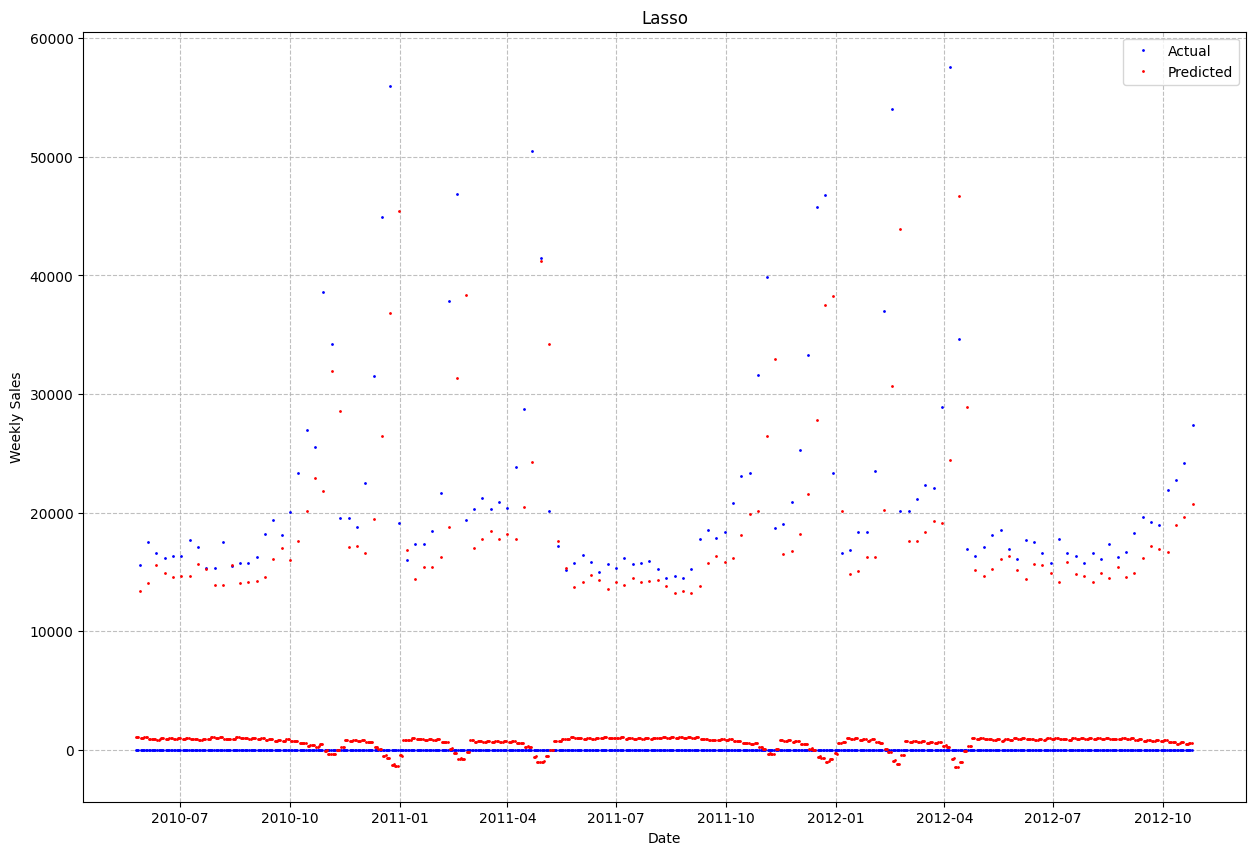

In [ ]:
#lasso
# Load data and preprocess
sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store'] == 1) & (sales_data['Dept'] == 1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 11):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.11)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

# Build a Lasso regression model
lasso = Lasso(alpha=0.1)  # You can try different values of alpha
lasso.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = lasso.predict(test[predictors])

# Calculate MAPE
mask = test[target] != 0
mape = np.mean(np.abs((test[target][mask] - predictions[mask]) / test[target][mask])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target][mask] - predictions[mask]) / test[target][mask]) * 100
print('MPE:', mpe)
# Plot actual vs predicted values
plt.figure(figsize=(15, 10))
plt.plot(test.index, test[target], ".", label='Actual', marker="o", markersize=1, color='blue')
plt.plot(test.index, predictions, ".", label='Predicted', marker="o", markersize=1, color='red')
plt.title('Lasso')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.8)
plt.show()


MAPE: 20.75535899229229
MPE: 5.754809061331415


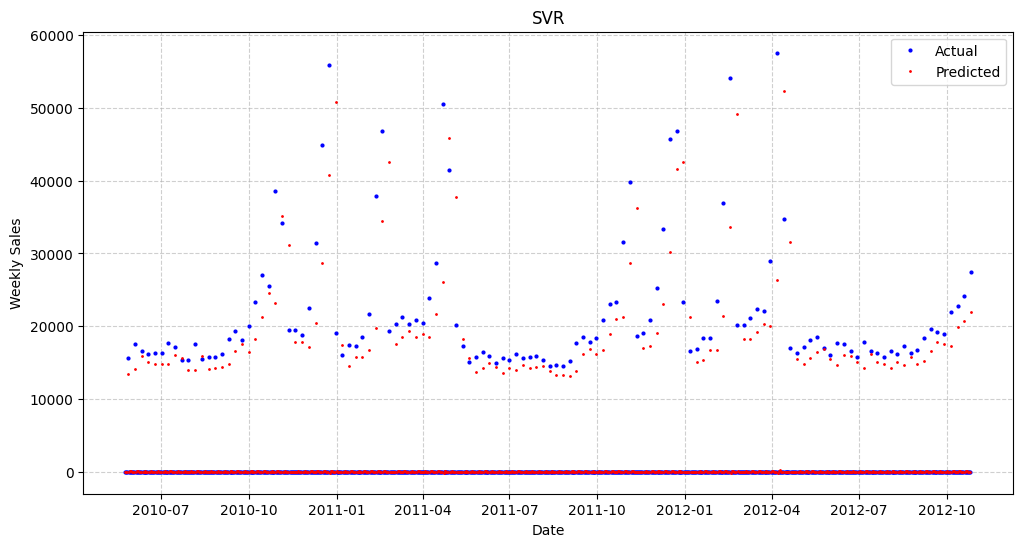

In [ ]:
#svr
# Load data and preprocess
sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store']==1) & (sales_data['Dept']==1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 11):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.11)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

# Build an SVM model
#here i changed the line as in code of idle
#svr = SVR(kernel='rbf', C=10, epsilon=0.1)
svr=SVR(kernel='linear')
svr.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = svr.predict(test[predictors])

# Calculate MAPE
mask = test[target] != 0
mape = np.mean(np.abs((test[target][mask] - predictions[mask]) / test[target][mask])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target][mask] - predictions[mask]) / test[target][mask]) * 100
print('MPE:', mpe)

# Plot actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(test.index, test[target], ".", label='Actual', marker="o", markersize=2, color='blue')
plt.plot(test.index, predictions, ".", label='Predicted', marker="o", markersize=1, color='red')
plt.title('SVR')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


MAPE: 15.426503469587544
MPE: -4.1083871025839125


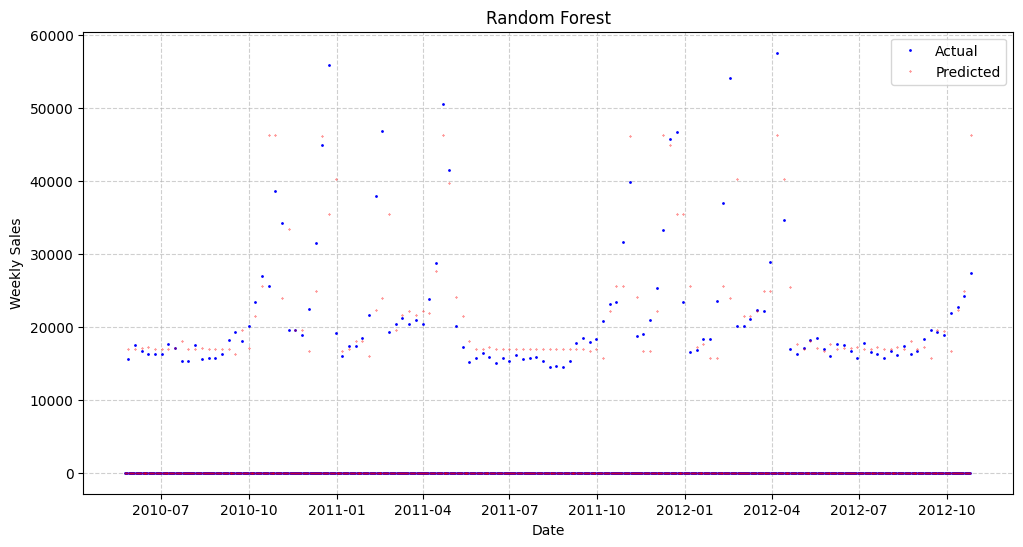

In [ ]:
#randomforest regressor
# Load data and preprocess
sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store']==1) & (sales_data['Dept']==1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 11):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.11)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

# Build a Random Forest model
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = rf_regressor.predict(test[predictors])

# Calculate MAPE
mask = test[target] != 0
mape = np.mean(np.abs((test[target][mask] - predictions[mask]) / test[target][mask])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target][mask] - predictions[mask]) / test[target][mask]) * 100
print('MPE:', mpe)

# Plot actual vs predicted values
# Plot actual vs predicted values with smaller dots
plt.figure(figsize=(12, 6))
plt.plot(test.index, test[target], ".", label='Actual', marker="o", markersize=1, color='blue')
plt.plot(test.index, predictions, ".", label='Predicted', marker="o", markersize=0.3, color='red')
plt.title('Random Forest')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()




















MAPE: 21.27394064122399
MPE: 9.5358257741799


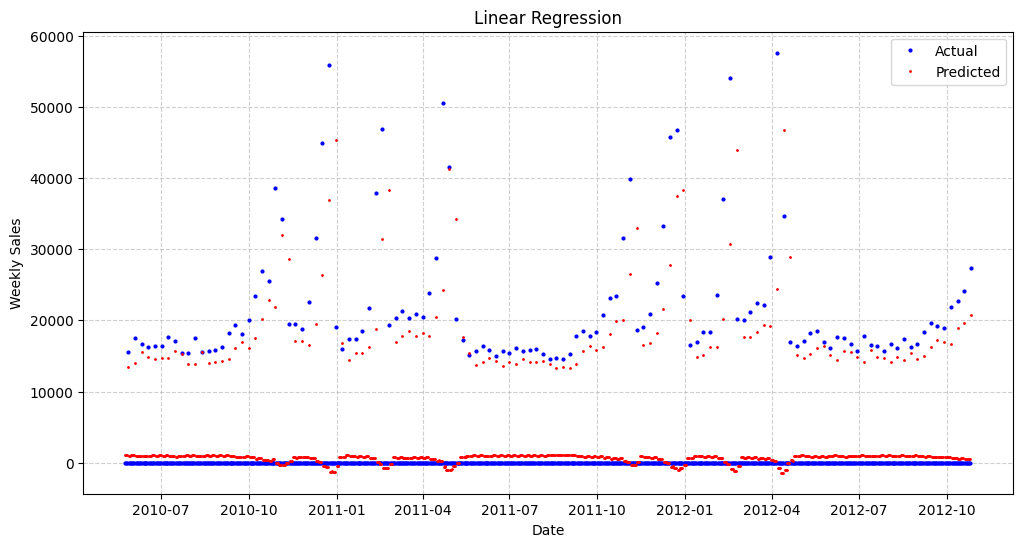

In [ ]:
#linear regression

sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store']==1) & (sales_data['Dept']==1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 11):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.11)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

model = LinearRegression()
model.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = model.predict(test[predictors])

# Calculate MAPE
mask = test[target] != 0
mape = np.mean(np.abs((test[target][mask] - predictions[mask]) / test[target][mask])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target][mask] - predictions[mask]) / test[target][mask]) * 100
print('MPE:', mpe)

# Plot actual vs predicted values
plt.figure(figsize=(12, 6))
plt.plot(test.index, test[target], ".", label='Actual', marker="o", markersize=2, color='blue')
plt.plot(test.index, predictions, ".", label='Predicted', marker="o", markersize=1, color='red')
plt.title('Linear Regression')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


MAPE: 18.236948463546952
MPE: -5.283864925122111


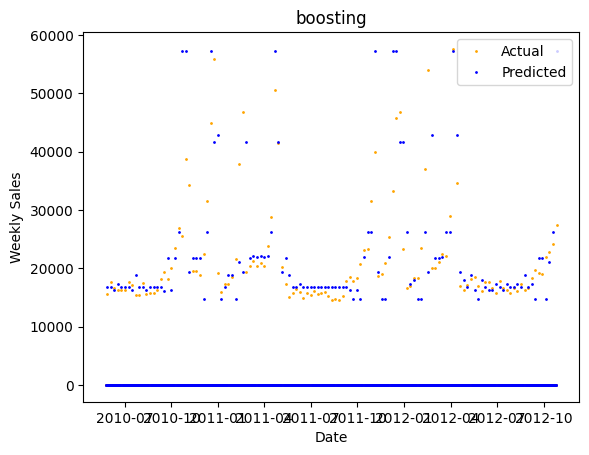

In [ ]:
#boosting(enemble)
import pandas as pd
import numpy as np
from sklearn.ensemble import AdaBoostRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

# Load data and preprocess
sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store'] == 1) & (sales_data['Dept'] == 1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 11):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.11)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

# Create base models
base_model1 = RandomForestRegressor(n_estimators=100, random_state=42)
base_model2 = Lasso(alpha=0.1)
base_model3 = LinearRegression()
base_model4 = SVR(kernel='linear')

# Create boosting model
from sklearn.ensemble import AdaBoostRegressor

boost_model = AdaBoostRegressor(
    estimator=base_model1,
    n_estimators=100,
    random_state=42
)
# Train the boosting model
boost_model.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = boost_model.predict(test[predictors])

# Calculate MAPE
mape = np.mean(np.abs((test[target] - predictions) / test[target])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target] - predictions) / test[target]) * 100
print('MPE:', mpe)


# Plot actual vs predicted values
test['predictions'] = predictions
plt.plot(test[target], ".", label='Actual', marker="o",markersize=1,color='orange')
plt.plot(test['predictions'], ".", label='Predicted', marker="o",markersize=1,color='blue')
plt.title('boosting')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')
plt.legend()
plt.show()


RMSE: 2486.89827274259
MAPE: 14.149583109804139
MPE: -1.2492544215016823


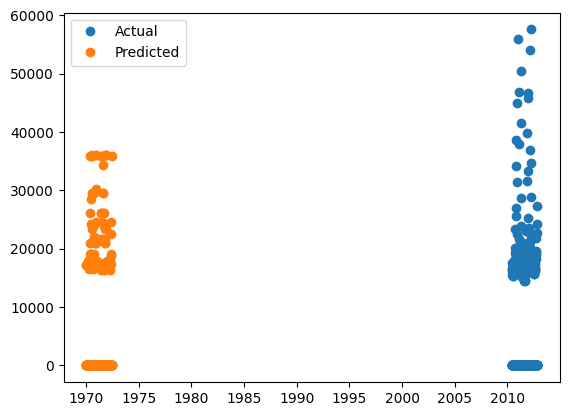

In [ ]:
#Bagging
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error

# Initialize the individual models
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
lasso = Lasso(alpha=0.1)
linear_regression = LinearRegression()
svr = SVR(kernel='linear')

# Create the Bagging Ensemble model
ensemble = BaggingRegressor(
    estimator=rf_regressor,
    n_estimators=10,
    random_state=42
)
# Fit the ensemble model on the training data
ensemble.fit(train[predictors], train[target])

# Make predictions on testing data
predictions = ensemble.predict(test[predictors])

# Calculate RMSE
rmse = np.sqrt(mean_squared_error(test[target], predictions))
print('RMSE:', rmse)

# Calculate MAPE
mape = np.mean(np.abs((test[target] - predictions) / test[target])) * 100
print('MAPE:', mape)

# Calculate MPE
mpe = np.mean((test[target] - predictions) / test[target]) * 100
print('MPE:', mpe)

# Plot actual vs predicted values
plt.plot(test[target], ".", label='Actual', marker="o")
plt.plot(predictions, ".", label='Predicted', marker="o")
plt.legend()
plt.show()


MAPE: 1.3620017929423421e+18
MPE: nan
RMSE: 2244.460589162229


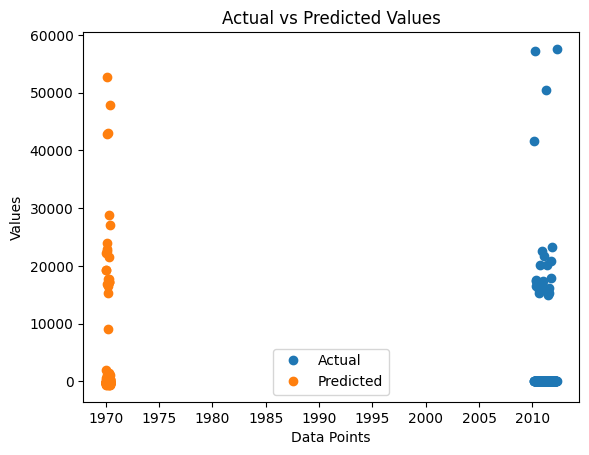

In [ ]:
#stacking
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_percentage_error

# Load data and preprocess
sales_data = pd.read_csv('/content/drive/MyDrive/Mini_Project/train.csv')
store_dept_sales = sales_data.loc[(sales_data['Store'] == 1) & (sales_data['Dept'] == 1)][['Weekly_Sales', 'Date']]
store_dept_sales['Date'] = pd.to_datetime(store_dept_sales['Date'])
store_dept_sales = store_dept_sales.set_index('Date')

# Resample weekly sales data to daily frequency
daily_sales = store_dept_sales.resample('D').sum()

# Create lag features
for i in range(1, 8):
    daily_sales[f'lag_{i}'] = daily_sales['Weekly_Sales'].shift(i)

# Split data into training and testing sets
train_size = int(len(daily_sales) * 0.8)
train, test = daily_sales[:train_size], daily_sales[train_size:]

# Drop missing values from training set
train = train.dropna()

# Define target variable and predictors
target = 'Weekly_Sales'
predictors = [col for col in train.columns if col != target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(train[predictors], train[target], test_size=0.2, random_state=42)

# Define the base estimators
lasso = Lasso()
svr = SVR()
rf = RandomForestRegressor()
linear_reg = LinearRegression()

# Train the base estimators
lasso.fit(X_train, y_train)
svr.fit(X_train, y_train)
rf.fit(X_train, y_train)
linear_reg.fit(X_train, y_train)

# Make predictions on the testing data
lasso_pred = lasso.predict(X_test)
svr_pred = svr.predict(X_test)
rf_pred = rf.predict(X_test)
linear_reg_pred = linear_reg.predict(X_test)

# Combine the predictions of the base estimators
stacked_pred = np.column_stack((lasso_pred, svr_pred, rf_pred, linear_reg_pred))

# Define the meta-model (final estimator)
meta_model = LinearRegression()
meta_model.fit(stacked_pred, y_test)

# Make predictions on the testing data using the meta-model
meta_pred = meta_model.predict(stacked_pred)

# Calculate MAPE and MPE
mape = mean_absolute_percentage_error(y_test, meta_pred)
print('MAPE:', mape)

# Calculate MPE
residuals = y_test - meta_pred
valid_indices = ~np.isnan(residuals) & ~np.isnan(y_test)
mpe = np.mean((residuals[valid_indices] / y_test[valid_indices]) * 100)
print('MPE:', mpe)


# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, meta_pred))
print('RMSE:', rmse)

# Plot actual vs predicted values
plt.plot(y_test, ".", label='Actual', marker="o")
plt.plot(meta_pred, ".", label='Predicted', marker="o")
plt.xlabel('Data Points')
plt.ylabel('Values')
plt.title('Actual vs Predicted Values')
plt.legend()
plt.show()
